## NBA Points Predictor - Bayesian Modeling
**- Owner:** Alex

**- Status:** Exploration only

**- Last Updated:** 10/27/26

In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("/Users/alexgonzalez/Documents/nba_quant")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [14]:
s20 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2019-20/regular_season/player_gamelogs.parquet')
s21 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2020-21/regular_season/player_gamelogs.parquet')
s22 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2021-22/regular_season/player_gamelogs.parquet')
s23 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2022-23/regular_season/player_gamelogs.parquet')
s24 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2023-24/regular_season/player_gamelogs.parquet')
s25 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2024-25/regular_season/player_gamelogs.parquet')
s26 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2025-26/regular_season/player_gamelogs.parquet')
s27 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2026-27/regular_season/player_gamelogs.parquet')
df = pd.concat([s20, s21, s22, s23, s24, s25, s26, s27]).reset_index(drop=True)
df['starting'] = (
    df['start_position'].astype('string').str.strip().isin(['G', 'F', 'C']).astype(int))
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(df.columns.tolist())
print(df.dtypes)
print(df.head().to_string())

Number of rows: 178335
Number of columns: 190
['season_year', 'player_id', 'player_name', 'nickname', 'team_id', 'team_abbreviation', 'team_name', 'game_id', 'game_date', 'matchup', 'wl', 'min', 'fgm', 'fga', 'fg_pct', 'fg3_m', 'fg3_a', 'fg3_pct', 'ftm', 'fta', 'ft_pct', 'oreb', 'dreb', 'reb', 'ast', 'tov', 'stl', 'blk', 'blka', 'pf', 'pfd', 'pts', 'plus_minus', 'nba_fantasy_pts', 'dd2', 'td3', 'wnba_fantasy_pts', 'fp_high_score', 'available_flag', 'min_sec', 'team_count', 'e_off_rating', 'off_rating', 'sp_work_off_rating', 'e_def_rating', 'def_rating', 'sp_work_def_rating', 'e_net_rating', 'net_rating', 'sp_work_net_rating', 'ast_pct', 'ast_to', 'ast_ratio', 'oreb_pct', 'dreb_pct', 'reb_pct', 'tm_tov_pct', 'e_tov_pct', 'efg_pct', 'ts_pct', 'usg_pct', 'e_usg_pct', 'e_pace', 'pace', 'pace_per40', 'sp_work_pace', 'pie', 'poss', 'fgm_pg', 'fga_pg', 'team_city', 'team_tricode', 'team_slug', 'first_name', 'family_name', 'name_i', 'player_slug', 'start_position', 'comment', 'jersey_num', 'mi

In [15]:
PLAYER_NAME = 'Brandon Miller'
LINE = 25.5

data = df[df['player_name'] == PLAYER_NAME]
data.tail(5)

,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,...,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
176809,2026-27,1641706,Brandon Miller,Brandon,1610612766,CHA,Charlotte Hornets,0022600134,2026-10-28T00:00:00,CHA @ DET,...,95.0,79.17,95,0.565,Regular Season,SF,213.0,-7.5,7.5,1
177158,2026-27,1641706,Brandon Miller,Brandon,1610612766,CHA,Charlotte Hornets,0022600119,2026-10-26T00:00:00,CHA vs. WAS,...,95.5,79.58,95,0.455,Regular Season,SF,226.0,-3.0,-3.0,1
177529,2026-27,1641706,Brandon Miller,Brandon,1610612766,CHA,Charlotte Hornets,0022600104,2026-10-24T00:00:00,CHA vs. MIA,...,101.5,84.58,102,0.489,Regular Season,SF,227.5,4.5,4.5,1
177855,2026-27,1641706,Brandon Miller,Brandon,1610612766,CHA,Charlotte Hornets,0022600094,2026-10-23T00:00:00,CHA vs. ATL,...,100.0,83.33,100,0.745,Regular Season,SF,226.5,-6.5,-6.5,1
178101,2026-27,1641706,Brandon Miller,Brandon,1610612766,CHA,Charlotte Hornets,0022600087,2026-10-21T00:00:00,CHA @ BKN,...,101.5,84.58,101,0.450,Regular Season,SF,219.5,-1.5,1.5,1


### Baseline Model

In [16]:
last5_game = data['pts'].tail(5).mean()
last10_game = data['pts'].tail(10).mean()
last20_game = data['pts'].tail(20).mean()
season_to_date  = data[data['season_year'] == '2026-27']['pts'].mean()
both_seasons = data.loc[data["season_year"].isin(["2025-26", "2026-27"]), "pts"].mean()

print(f"Last 5 games: {last5_game:.2f}")
print(f"Last 10 games: {last10_game:.2f}")
print(f"Last 20 games: {last20_game:.2f}")
print(f"Season to date: {season_to_date:.2f}")
print(f"Both seasons: {both_seasons:.2f}")

Last 5 games: 25.60
Last 10 games: 22.30
Last 20 games: 19.85
Season to date: 25.60
Both seasons: 20.56


In [17]:
def over_rate(pts):
    scored = pts.dropna()
    if len(scored) == 0:
        raise ValueError(f"no points for {PLAYER_NAME}")
    n_over = int((scored > LINE).sum())
    return n_over / len(scored), n_over, len(scored)

windows = {
    "Last 5 games": data["pts"].tail(5),
    "Last 10 games": data["pts"].tail(10),
    "Last 20 games": data["pts"].tail(20),
    "Season to date": data.loc[data["season_year"] == "2026-27", "pts"],
    "Both seasons": data.loc[data["season_year"].isin(["2025-26", "2026-27"]), "pts"],
}

for name, pts in windows.items():
    rate, n_over, n_games = over_rate(pts)
    print(f"{name}: P(pts > {LINE:.1f}) = {rate:.3f} ({n_over}/{n_games})")

Last 5 games: P(pts > 25.5) = 0.600 (3/5)
Last 10 games: P(pts > 25.5) = 0.400 (4/10)
Last 20 games: P(pts > 25.5) = 0.250 (5/20)
Season to date: P(pts > 25.5) = 0.600 (3/5)
Both seasons: P(pts > 25.5) = 0.243 (17/70)


### Bayesian Normal Model

The unknown is μ, the player's typical scoring level. Each game is noise around that level:

y | μ ~ Normal(μ, σ²)

σ² is the 2025-26 sample variance and stays fixed. The prior is that season's mean. Its variance is the standard error of the mean, σ² / n₀, so last season counts as n₀ games of evidence.

Each new game adds one game of evidence. After n new games with mean ȳ:

posterior mean = (n₀ μ₀ + n ȳ) / (n₀ + n)

posterior variance = σ² / (n₀ + n)

Static: one player, a hand-picked prior.

θ ~ Beta(a, b) with a, b chosen by you
k ~ Binomial(n, θ)

In [18]:
import math


def normal_mean_posterior(prior_pts, observed_pts):
    """Update a normal mean. Variance is fixed from the prior games."""
    prior = prior_pts.dropna()
    observed = observed_pts.dropna()
    if len(prior) < 2:
        raise ValueError("need at least two prior games to fix the variance")
    sigma2 = float(prior.var(ddof=1))
    if not math.isfinite(sigma2) or sigma2 <= 0:
        raise ValueError("known variance must be positive and finite")
    n0 = len(prior)
    mu0 = float(prior.mean())
    n = len(observed)
    total = float(observed.sum()) if n else 0.0
    mu_n = (n0 * mu0 + total) / (n0 + n)
    return {
        "n0": n0,
        "mu0": mu0,
        "sigma2": sigma2,
        "sigma": math.sqrt(sigma2),
        "tau0": math.sqrt(sigma2 / n0),
        "n": n,
        "mu_n": mu_n,
        "tau_n": math.sqrt(sigma2 / (n0 + n)),
    }


def std_normal_sf(z):
    """P(Z > z) for a standard normal Z."""
    return 0.5 * (1.0 - math.erf(z / math.sqrt(2.0)))


chrono = data.sort_values(["game_date", "game_id"], kind="mergesort")
prior_pts = chrono.loc[chrono["season_year"] == "2025-26", "pts"]
season_games = chrono.loc[
    chrono["season_year"] == "2026-27", ["game_date", "pts"]
].dropna()
if season_games.empty:
    raise ValueError(f"no 2026-27 points for {PLAYER_NAME}")

steps = []
for i in range(len(season_games)):
    fit = normal_mean_posterior(prior_pts, season_games["pts"].iloc[: i + 1])
    game = season_games.iloc[i]
    steps.append((str(game["game_date"])[:10], float(game["pts"]), fit))

fit = steps[-1][2]
pooled = pd.concat([prior_pts.dropna(), season_games["pts"]]).mean()
if abs(fit["mu_n"] - pooled) > 1e-9:
    raise AssertionError("posterior mean must equal the pooled mean when the prior has n0 votes")
lo = fit["mu_n"] - 1.96 * fit["tau_n"]
hi = fit["mu_n"] + 1.96 * fit["tau_n"]
p_level = std_normal_sf((LINE - fit["mu_n"]) / fit["tau_n"])
pred_sd = math.sqrt(fit["sigma2"] + fit["tau_n"] ** 2)
p_next = std_normal_sf((LINE - fit["mu_n"]) / pred_sd)

print(
    f"Prior (2025-26): mean {fit['mu0']:.2f} from {fit['n0']} games, "
    f"game sd {fit['sigma']:.2f}, mean sd {fit['tau0']:.2f}"
)
for date, pts, step in steps:
    label = "game" if step["n"] == 1 else "games"
    print(
        f"After {date} ({pts:.0f} pts, {step['n']} new {label}): "
        f"mean {step['mu_n']:.2f} (sd {step['tau_n']:.2f})"
    )
print(f"95% interval for typical level: [{lo:.2f}, {hi:.2f}]")
print(f"P(typical level > {LINE:.1f}) = {p_level:.3f}")
print(f"P(next game > {LINE:.1f}) = {p_next:.3f}")

Prior (2025-26): mean 20.17 from 65 games, game sd 6.66, mean sd 0.83
After 2026-10-21 (18 pts, 1 new game): mean 20.14 (sd 0.82)
After 2026-10-23 (6 pts, 2 new games): mean 19.93 (sd 0.81)
After 2026-10-24 (34 pts, 3 new games): mean 20.13 (sd 0.81)
After 2026-10-26 (39 pts, 4 new games): mean 20.41 (sd 0.80)
After 2026-10-28 (31 pts, 5 new games): mean 20.56 (sd 0.80)
95% interval for typical level: [19.00, 22.12]
P(typical level > 25.5) = 0.000
P(next game > 25.5) = 0.231


### Bayesian Predictive Distribution

The next game is a draw from the predictive distribution, not a statement about the average. The scoring level μ and the game-to-game variance σ² are both unknown.

A flat prior updated with the 2025-26 games is the prior. The 2026-27 games update the average and the variance together. The next game then follows a Student-t:

center = posterior mean of the scoring level

degrees of freedom = (games in the prior and the update) − 1

scale = s √(1 + 1/n)

s is the sample standard deviation of those games. The scale is wider than s because the average is still uncertain, and the t tails are wider than a normal curve because s itself is uncertain.

P(points > 16.5) is the upper tail of that distribution. The 95% interval can extend below zero because this model does not enforce a floor at zero points.

Next game ~ Student-t(df=69, center=20.56, scale=7.37)
Predictive sd = 7.48
10th / 50th / 90th percentile: 11.0 / 20.6 / 30.1
95% interval for the next game: [5.85, 35.26]
P(points > 25.5) = 0.252
Variance fixed at the 2025-26 estimate: sd 6.71, P(points > 25.5) = 0.231


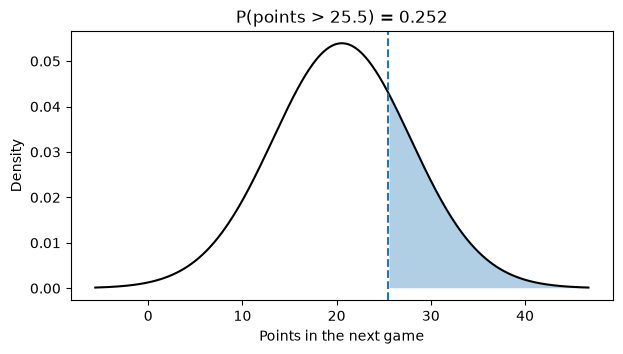

In [19]:
import math

import numpy as np
from scipy import stats


def nig_from_sample(pts):
    """Posterior of (mean, variance) after a flat prior and these games."""
    values = pts.dropna().to_numpy(dtype=float)
    if len(values) < 2:
        raise ValueError("need at least two games")
    center = float(values.mean())
    sse = float(np.sum((values - center) ** 2))
    n = len(values)
    return {"kappa": n, "mu": center, "alpha": (n - 1) / 2, "beta": 0.5 * sse}


def nig_update(state, pts):
    """Conjugate update for new games."""
    values = pts.dropna().to_numpy(dtype=float)
    if len(values) == 0:
        raise ValueError("no observed games")
    n = len(values)
    ybar = float(values.mean())
    sse = float(np.sum((values - ybar) ** 2))
    kappa = state["kappa"] + n
    mu = (state["kappa"] * state["mu"] + n * ybar) / kappa
    alpha = state["alpha"] + n / 2
    beta = (
        state["beta"]
        + 0.5 * sse
        + (state["kappa"] * n) / (2 * kappa) * (ybar - state["mu"]) ** 2
    )
    return {"kappa": kappa, "mu": mu, "alpha": alpha, "beta": beta}


def predictive_student_t(state):
    """Location, degrees of freedom, and scale of the next-game distribution."""
    if state["alpha"] <= 0 or state["beta"] <= 0 or state["kappa"] <= 0:
        raise ValueError("predictive scale is undefined")
    degrees = 2 * state["alpha"]
    loc = state["mu"]
    scale = math.sqrt((state["beta"] / state["alpha"]) * (1 + 1 / state["kappa"]))
    return degrees, loc, scale


chrono = data.sort_values(["game_date", "game_id"], kind="mergesort")
prior_pts = chrono.loc[chrono["season_year"] == "2025-26", "pts"]
season_pts = chrono.loc[chrono["season_year"] == "2026-27", "pts"].dropna()
if season_pts.empty:
    raise ValueError(f"no 2026-27 points for {PLAYER_NAME}")

posterior = nig_update(nig_from_sample(prior_pts), season_pts)
oneshot = nig_from_sample(pd.concat([prior_pts.dropna(), season_pts]))
for key in ("kappa", "mu", "alpha", "beta"):
    if abs(posterior[key] - oneshot[key]) > 1e-6:
        raise AssertionError(f"{key} disagrees between the sequential update and the pooled sample")

degrees, loc, scale = predictive_student_t(posterior)
pred_sd = scale * math.sqrt(degrees / (degrees - 2))
p_over = float(stats.t.sf(LINE, degrees, loc=loc, scale=scale))
lo, hi = stats.t.interval(0.95, degrees, loc=loc, scale=scale)
q10, q50, q90 = stats.t.ppf([0.10, 0.50, 0.90], degrees, loc=loc, scale=scale)

sigma2 = float(prior_pts.dropna().var(ddof=1))
n_total = posterior["kappa"]
known_sd = math.sqrt(sigma2 * (1 + 1 / n_total))
p_known = float(stats.norm.sf(LINE, loc=loc, scale=known_sd))

print(f"Next game ~ Student-t(df={degrees:.0f}, center={loc:.2f}, scale={scale:.2f})")
print(f"Predictive sd = {pred_sd:.2f}")
print(f"10th / 50th / 90th percentile: {q10:.1f} / {q50:.1f} / {q90:.1f}")
print(f"95% interval for the next game: [{lo:.2f}, {hi:.2f}]")
print(f"P(points > {LINE:.1f}) = {p_over:.3f}")
print(f"Variance fixed at the 2025-26 estimate: sd {known_sd:.2f}, P(points > {LINE:.1f}) = {p_known:.3f}")

xs = np.linspace(loc - 3.5 * pred_sd, loc + 3.5 * pred_sd, 400)
density = stats.t.pdf(xs, degrees, loc=loc, scale=scale)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(xs, density, color="black")
ax.fill_between(xs, density, where=xs > LINE, alpha=0.35)
ax.axvline(LINE, color="C0", linestyle="--")
ax.set_xlabel("Points in the next game")
ax.set_ylabel("Density")
ax.set_title(f"P(points > {LINE:.1f}) = {p_over:.3f}")
plt.show()

### Bayesian Regression

The regression predicts points from information known before the game. Last game's minutes, field-goal attempts, and free-throw attempts describe the recent role. Rest is the number of days since his previous game this season. Opponent context is that opponent's average defensive rating over their previous 10 games. Home or away is the remaining pregame indicator. Same-game minutes and shot attempts are not predictors, and the 2026-27 games are not in the fit.

Predictors are standardized. Each slope has a normal prior with standard deviation 2.5 residual standard deviations, which is weak. Residual variance has an inverse-gamma prior with mean 50. Results below are converted back to original units. A higher opponent defensive rating means that opponent has been allowing more points.

The career fit is driven largely by the move from a small role to a large one. The 2024-25 and 2025-26 fit asks whether last game's role still changes the prediction once that larger role is already the baseline.

In [20]:
import math

import numpy as np
from scipy import stats

FEATURES = [
    "min_lag_1",
    "fga_lag_1",
    "fta_lag_1",
    "rest_days",
    "opp_def_prior",
    "is_home",
]
SLOPE_PRIOR_SD = 2.5
INTERCEPT_PRIOR_SD = 100.0
PRIOR_A = 2.0
PRIOR_B = 50.0


def bayesian_regression(frame):
    """Normal-inverse-gamma regression. Slopes use a weak prior on standardized predictors."""
    y = frame["pts"].to_numpy(dtype=float)
    raw = frame[FEATURES].to_numpy(dtype=float)
    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    if np.any(~np.isfinite(scale)) or np.any(scale <= 0):
        raise ValueError("a predictor has no variation")
    design = np.column_stack([np.ones(len(frame)), (raw - center) / scale])
    n_rows, n_coef = design.shape
    prior_precision = np.full(n_coef, 1 / SLOPE_PRIOR_SD**2)
    prior_precision[0] = 1 / INTERCEPT_PRIOR_SD**2
    lam0 = np.diag(prior_precision)
    lam = lam0 + design.T @ design
    np.linalg.cholesky(lam)
    coef = np.linalg.solve(lam, design.T @ y)
    a_n = PRIOR_A + n_rows / 2
    b_n = PRIOR_B + 0.5 * float(y @ y - coef @ lam @ coef)
    if not math.isfinite(b_n) or b_n <= 0 or a_n <= 1:
        raise ValueError("posterior variance is undefined")
    return {
        "n": n_rows,
        "center": center,
        "scale": scale,
        "coef": coef,
        "lam": lam,
        "a": a_n,
        "b": b_n,
        "df": 2 * a_n,
    }


def contrast_interval(fit, delta):
    """Posterior mean and 95% interval for a change in the raw predictors."""
    contrast = np.zeros(len(fit["coef"]))
    contrast[1:] = np.asarray(delta, dtype=float) / fit["scale"]
    estimate = float(contrast @ fit["coef"])
    spread = math.sqrt(
        (fit["b"] / fit["a"]) * float(contrast @ np.linalg.solve(fit["lam"], contrast))
    )
    critical = float(stats.t.ppf(0.975, fit["df"]))
    return estimate, estimate - critical * spread, estimate + critical * spread


def predictive_at(fit, raw_row):
    z_score = (np.asarray(raw_row, dtype=float) - fit["center"]) / fit["scale"]
    row = np.concatenate([[1.0], z_score])
    loc = float(row @ fit["coef"])
    scale = math.sqrt(
        (fit["b"] / fit["a"]) * (1 + float(row @ np.linalg.solve(fit["lam"], row)))
    )
    p_over = float(stats.t.sf(LINE, fit["df"], loc=loc, scale=scale))
    return loc, p_over


player = data.sort_values(["game_date", "game_id"], kind="mergesort").copy()
player["game_date"] = pd.to_datetime(player["game_date"])
for source, lagged in (("minutes", "min_lag_1"), ("fga", "fga_lag_1"), ("fta", "fta_lag_1")):
    player[lagged] = pd.to_numeric(player[source], errors="coerce").shift(1)
player["rest_days"] = player.groupby("season_year", sort=False)["game_date"].diff().dt.days
player["is_home"] = player["matchup"].astype(str).str.contains("vs", case=False).astype(float)

teams = (
    df[["team_id", "game_id", "game_date", "team_def_rating"]]
    .drop_duplicates(["team_id", "game_id"])
    .sort_values(["team_id", "game_date", "game_id"], kind="mergesort")
)
teams["team_def_rating"] = pd.to_numeric(teams["team_def_rating"], errors="coerce")
prior_defense = teams.groupby("team_id", sort=False)["team_def_rating"].shift(1)
teams["opp_def_prior"] = (
    prior_defense.groupby(teams["team_id"], sort=False)
    .rolling(10, min_periods=3)
    .mean()
    .reset_index(level=0, drop=True)
)
player = player.merge(
    teams[["game_id", "team_id", "opp_def_prior"]].rename(columns={"team_id": "opp_team_id"}),
    on=["game_id", "opp_team_id"],
    how="left",
    validate="many_to_one",
)

history = player.loc[player["season_year"] != "2026-27"].copy()
complete = history.dropna(subset=FEATURES + ["pts"])
played = complete.loc[pd.to_numeric(complete["minutes"], errors="coerce") > 0].copy()
n_dropped = len(history) - len(played)
if played.empty:
    raise ValueError(f"no complete pre-2026-27 games for {PLAYER_NAME}")
print(
    f"Left out {n_dropped} pre-2026-27 games with missing predictors, missing points, or zero minutes."
)

LABELS = {
    "min_lag_1": "lagged minutes, per minute",
    "fga_lag_1": "lagged field-goal attempts, per attempt",
    "fta_lag_1": "lagged free-throw attempts, per attempt",
    "rest_days": "rest, per extra day",
    "opp_def_prior": "softer opponent defense, per rating point",
    "is_home": "home instead of away",
}


def report(title, frame):
    fit = bayesian_regression(frame)
    print(f"\n{title}: {fit['n']} games")
    for index, name in enumerate(FEATURES):
        estimate, low, high = contrast_interval(fit, np.eye(len(FEATURES))[index])
        print(f"  {LABELS[name]}: {estimate:+.2f}  [{low:+.2f}, {high:+.2f}]")
    role = np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0])
    defense = np.array([0.0, 0.0, 0.0, 0.0, 5.0, 0.0])
    for label, delta in (
        ("role +5 minutes, +3 FGA, +1 FTA", role),
        ("opponent defense 5 points softer", defense),
    ):
        estimate, low, high = contrast_interval(fit, delta)
        print(f"  {label}: {estimate:+.2f} points  [{low:+.2f}, {high:+.2f}]")
    return fit

career = report("Career before 2026-27", played)
recent = played.loc[played["season_year"].isin(["2024-25", "2025-26"])].copy()
report("2024-25 and 2025-26 only", recent)

baseline = played.loc[played["season_year"] == "2025-26", FEATURES].mean().to_numpy(dtype=float)
base_mean, base_over = predictive_at(career, baseline)
role_mean, role_over = predictive_at(career, baseline + np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0]))
defense_mean, defense_over = predictive_at(
    career, baseline + np.array([0.0, 0.0, 0.0, 0.0, 5.0, 0.0])
)
print("\nCareer model at his 2025-26 average role")
print(f"  baseline: {base_mean:.2f} points, P(points > {LINE:.1f}) = {base_over:.3f}")
print(f"  larger role: {role_mean:.2f} points, P(points > {LINE:.1f}) = {role_over:.3f}")
print(
    f"  softer defense: {defense_mean:.2f} points, P(points > {LINE:.1f}) = {defense_over:.3f}"
)

Left out 3 pre-2026-27 games with missing predictors, missing points, or zero minutes.

Career before 2026-27: 163 games
  lagged minutes, per minute: -0.09  [-0.31, +0.14]
  lagged field-goal attempts, per attempt: +0.45  [+0.14, +0.75]
  lagged free-throw attempts, per attempt: +0.07  [-0.40, +0.54]
  rest, per extra day: -0.06  [-0.51, +0.39]
  softer opponent defense, per rating point: +0.00  [-0.23, +0.24]
  home instead of away: +2.09  [-0.05, +4.24]
  role +5 minutes, +3 FGA, +1 FTA: +0.96 points  [-0.00, +1.93]
  opponent defense 5 points softer: +0.02 points  [-1.16, +1.21]

2024-25 and 2025-26 only: 90 games
  lagged minutes, per minute: +0.12  [-0.22, +0.46]
  lagged field-goal attempts, per attempt: +0.20  [-0.21, +0.61]
  lagged free-throw attempts, per attempt: -0.22  [-0.79, +0.35]
  rest, per extra day: -0.06  [-0.53, +0.41]
  softer opponent defense, per rating point: +0.12  [-0.21, +0.45]
  home instead of away: +2.22  [-0.61, +5.05]
  role +5 minutes, +3 FGA, +1 FTA:

### Hierarchical Bayesian Model

This combines partial pooling with the pregame regression. For game *g* by player *i*:

pointsᵢg = shared pregame regression + position effect + team effect + player effect + noise

Position, team, and player effects have zero-centered normal priors. Their prior precisions act like pseudo-games: 20 for position, 20 for team, and 10 for player. A one-game player's identity estimate is therefore pulled strongly toward the position-and-team baseline; an established player's estimate is driven mostly by his own history. A player unseen in training receives no player effect but still receives the shared role, position, and team effects.

The common predictors are lagged minutes, FGA, FTA, rest, opponent defensive context, and home court. This separates role from player identity: changing expected opportunities moves the shared regression component without pretending that the player's underlying scoring level changed permanently.

The model is fitted on 2024-25 and 2025-26 only. The 2026-27 games remain untouched. The posterior and predictive distribution are available analytically because every coefficient has a normal prior and the residual variance has an inverse-gamma prior. This is a deliberately simple hierarchy; the pseudo-game strengths are modeling assumptions, not values selected on the holdout.

In [21]:
from scipy import sparse
from scipy.sparse.linalg import splu

HIER_FEATURES = [
    "min_lag_1",
    "fga_lag_1",
    "fta_lag_1",
    "rest_days",
    "opp_def_prior",
    "is_home",
]
HIER_TRAIN_SEASONS = ["2024-25", "2025-26"]
POSITION_PSEUDO_GAMES = 20.0
TEAM_PSEUDO_GAMES = 20.0
PLAYER_PSEUDO_GAMES = 10.0


def hierarchical_frame(games):
    """Build causal game-level predictors for every player."""
    frame = games.copy()
    frame["game_date"] = pd.to_datetime(frame["game_date"])
    frame = frame.sort_values(
        ["player_id", "game_date", "game_id"], kind="mergesort"
    )
    for source, lagged in (
        ("minutes", "min_lag_1"),
        ("fga", "fga_lag_1"),
        ("fta", "fta_lag_1"),
    ):
        numeric = pd.to_numeric(frame[source], errors="coerce")
        frame[lagged] = numeric.groupby(frame["player_id"], sort=False).shift(1)
    frame["rest_days"] = (
        frame.groupby(["player_id", "season_year"], sort=False)["game_date"]
        .diff()
        .dt.days
    )
    frame["is_home"] = (
        frame["matchup"].astype(str).str.contains("vs", case=False).astype(float)
    )

    teams = (
        frame[["team_id", "game_id", "game_date", "team_def_rating"]]
        .drop_duplicates(["team_id", "game_id"])
        .sort_values(["team_id", "game_date", "game_id"], kind="mergesort")
    )
    teams["team_def_rating"] = pd.to_numeric(
        teams["team_def_rating"], errors="coerce"
    )
    prior_defense = teams.groupby("team_id", sort=False)["team_def_rating"].shift(1)
    teams["opp_def_prior"] = (
        prior_defense.groupby(teams["team_id"], sort=False)
        .rolling(10, min_periods=3)
        .mean()
        .reset_index(level=0, drop=True)
    )
    opponent = teams[["game_id", "team_id", "opp_def_prior"]].rename(
        columns={"team_id": "opp_team_id"}
    )
    return frame.merge(
        opponent,
        on=["game_id", "opp_team_id"],
        how="left",
        validate="many_to_one",
    )


def category_map(values):
    unique = sorted(pd.Series(values).dropna().unique().tolist())
    return {value: index for index, value in enumerate(unique)}


def one_hot(values, mapping):
    row = np.arange(len(values))
    column = np.array([mapping[value] for value in values])
    return sparse.csr_matrix(
        (np.ones(len(values)), (row, column)),
        shape=(len(values), len(mapping)),
    )


def fit_hierarchical_points(frame):
    """Conjugate Bayesian regression with position, team, and player effects."""
    raw = frame[HIER_FEATURES].to_numpy(dtype=float)
    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    if np.any(~np.isfinite(scale)) or np.any(scale <= 0):
        raise ValueError("a hierarchical predictor has no variation")

    position_map = category_map(frame["pos"].astype(str))
    team_map = category_map(frame["team_id"])
    player_map = category_map(frame["player_id"])
    common = sparse.csr_matrix(
        np.column_stack([np.ones(len(frame)), (raw - center) / scale])
    )
    design = sparse.hstack(
        [
            common,
            one_hot(frame["pos"].astype(str), position_map),
            one_hot(frame["team_id"], team_map),
            one_hot(frame["player_id"], player_map),
        ],
        format="csc",
    )

    n_common = 1 + len(HIER_FEATURES)
    precision = np.concatenate(
        [
            [1e-6],
            np.full(len(HIER_FEATURES), 1 / 2.5**2),
            np.full(len(position_map), POSITION_PSEUDO_GAMES),
            np.full(len(team_map), TEAM_PSEUDO_GAMES),
            np.full(len(player_map), PLAYER_PSEUDO_GAMES),
        ]
    )
    posterior_precision = (
        design.T @ design + sparse.diags(precision, format="csc")
    ).tocsc()
    factor = splu(posterior_precision)
    y = frame["pts"].to_numpy(dtype=float)
    xty = np.asarray(design.T @ y).ravel()
    coef = factor.solve(xty)
    alpha = 2.0 + len(frame) / 2
    beta = 50.0 + 0.5 * float(y @ y - coef @ xty)
    if not np.isfinite(coef).all() or not math.isfinite(beta) or beta <= 0:
        raise ValueError("hierarchical posterior is not finite")

    return {
        "n": len(frame),
        "center": center,
        "scale": scale,
        "coef": coef,
        "factor": factor,
        "alpha": alpha,
        "beta": beta,
        "df": 2 * alpha,
        "position_map": position_map,
        "team_map": team_map,
        "player_map": player_map,
        "n_common": n_common,
    }


def hierarchical_row(fit, raw, position, team_id, player_id=None):
    """Create a prediction row; unseen identities receive a zero player effect."""
    n_position = len(fit["position_map"])
    n_team = len(fit["team_map"])
    row = np.zeros(len(fit["coef"]))
    row[0] = 1.0
    row[1 : fit["n_common"]] = (
        np.asarray(raw, dtype=float) - fit["center"]
    ) / fit["scale"]
    position = str(position)
    if position in fit["position_map"]:
        row[fit["n_common"] + fit["position_map"][position]] = 1.0
    if team_id in fit["team_map"]:
        row[
            fit["n_common"] + n_position + fit["team_map"][team_id]
        ] = 1.0
    if player_id in fit["player_map"]:
        row[
            fit["n_common"]
            + n_position
            + n_team
            + fit["player_map"][player_id]
        ] = 1.0
    return row


def hierarchical_predict(fit, row, line=LINE):
    """Posterior predictive center, scale, and over probability."""
    loc = float(row @ fit["coef"])
    leverage = float(row @ fit["factor"].solve(row))
    scale = math.sqrt(
        (fit["beta"] / fit["alpha"]) * (1.0 + leverage)
    )
    probability = float(
        stats.t.sf(line, fit["df"], loc=loc, scale=scale)
    )
    return {"mean": loc, "scale": scale, "p_over": probability}


hier_data = hierarchical_frame(df)
required = HIER_FEATURES + ["pts", "player_id", "pos", "team_id"]
train_candidates = hier_data.loc[
    hier_data["season_year"].isin(HIER_TRAIN_SEASONS)
].copy()
hier_train = train_candidates.dropna(subset=required).copy()
hier_train = hier_train.loc[
    pd.to_numeric(hier_train["minutes"], errors="coerce") > 0
].copy()
print(
    f"Training rows: {len(hier_train):,}; excluded incomplete/zero-minute rows: "
    f"{len(train_candidates) - len(hier_train):,}; players: "
    f"{hier_train['player_id'].nunique()}"
)
if (hier_train["season_year"] == "2026-27").any():
    raise AssertionError("2026-27 leaked into the hierarchy")

hier_fit = fit_hierarchical_points(hier_train)
latest = (
    hier_data.loc[hier_data["player_name"] == PLAYER_NAME]
    .sort_values(["game_date", "game_id"])
    .iloc[-1]
)
player_id = latest["player_id"]
role = hier_train.loc[
    (hier_train["player_id"] == player_id)
    & (hier_train["season_year"] == "2025-26"),
    HIER_FEATURES,
].mean().to_numpy(dtype=float)
if not np.isfinite(role).all():
    raise ValueError(f"no complete 2025-26 role baseline for {PLAYER_NAME}")

player_row = hierarchical_row(
    hier_fit, role, latest["pos"], latest["team_id"], player_id
)
new_player_row = hierarchical_row(
    hier_fit, role, latest["pos"], latest["team_id"], player_id=None
)
larger_role_row = hierarchical_row(
    hier_fit,
    role + np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0]),
    latest["pos"],
    latest["team_id"],
    player_id,
)
player_prediction = hierarchical_predict(hier_fit, player_row)
peer_prediction = hierarchical_predict(hier_fit, new_player_row)
role_prediction = hierarchical_predict(hier_fit, larger_role_row)

n_position = len(hier_fit["position_map"])
n_team = len(hier_fit["team_map"])
player_offset = hier_fit["n_common"] + n_position + n_team
player_effect = hier_fit["coef"][
    player_offset + hier_fit["player_map"][player_id]
]
if abs(
    player_prediction["mean"] - peer_prediction["mean"] - player_effect
) > 1e-8:
    raise AssertionError("player partial-pooling effect is not isolated correctly")

print(f"\n{PLAYER_NAME} at his 2025-26 average role")
print(
    f"  unseen-player position/team baseline: {peer_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {peer_prediction['p_over']:.3f}"
)
print(
    f"  with learned player effect ({player_effect:+.2f}): "
    f"{player_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {player_prediction['p_over']:.3f}"
)
print(
    f"  larger role (+5 minutes, +3 FGA, +1 FTA): "
    f"{role_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {role_prediction['p_over']:.3f}"
)
print(
    f"  role change: {role_prediction['mean'] - player_prediction['mean']:+.2f} points"
)

player_summary = (
    hier_train.groupby(["player_id", "player_name"], as_index=False)
    .agg(games=("pts", "size"), raw_mean=("pts", "mean"))
)
last_context = (
    hier_train.sort_values(["game_date", "game_id"])
    .groupby("player_id", sort=False)
    .tail(1)
    .set_index("player_id")
)
pooled = []
for record in player_summary.itertuples():
    context = last_context.loc[record.player_id]
    average_role = hier_train.loc[
        hier_train["player_id"] == record.player_id, HIER_FEATURES
    ].mean().to_numpy(dtype=float)
    row = hierarchical_row(
        hier_fit,
        average_role,
        context["pos"],
        context["team_id"],
        record.player_id,
    )
    pooled.append(hierarchical_predict(hier_fit, row)["mean"])
player_summary["pooled_mean"] = pooled
player_summary["shrinkage"] = (
    player_summary["pooled_mean"] - player_summary["raw_mean"]
)
print("\nSmallest samples: raw mean -> partially pooled prediction")
print(
    player_summary.sort_values(["games", "player_name"])
    .head(10)[["player_name", "games", "raw_mean", "pooled_mean", "shrinkage"]]
    .round(2)
    .to_string(index=False)
)

Training rows: 51,632; excluded incomplete/zero-minute rows: 1,325; players: 679

Brandon Miller at his 2025-26 average role
  unseen-player position/team baseline: 13.00 points, P(over 25.5) = 0.020
  with learned player effect (+6.57): 19.57 points, P(over 25.5) = 0.167
  larger role (+5 minutes, +3 FGA, +1 FTA): 21.10 points, P(over 25.5) = 0.237
  role change: +1.53 points

Smallest samples: raw mean -> partially pooled prediction
     player_name  games  raw_mean  pooled_mean  shrinkage
  Chucky Hepburn      1       0.0         5.81       5.81
   Jesse Edwards      1       0.0         3.35       3.35
 Lawson Lovering      1      11.0         8.54      -2.46
Mouhamadou Gueye      1      11.0         9.07      -1.93
    Noa Essengue      1       0.0         5.97       5.97
  Quincy Olivari      1       0.0         4.87       4.87
      Taze Moore      1       2.0         7.61       5.61
    Yuri Collins      1       0.0         6.70       6.70
     Braxton Key      2       1.5      

### Dynamic Hierarchical Bayesian Model

The static hierarchy gives each player one identity effect. Here that effect becomes a latent state that follows a random walk:

abilityₜ = abilityₜ₋₁ + evolution noise

pointsₜ = shared role/context predictionₜ + abilityₜ + game noise

The shared regression still handles immediately observable changes in minutes, shot volume, rest, opponent, home court, position, and team. The latent state handles slower changes that remain after those inputs are accounted for. Each completed game updates the state with a Kalman step. No current game's points enter its own pregame prediction.

The state drifts by 0.35 points per game and receives 2.0 points of additional uncertainty across the offseason. These are explicit assumptions, not values selected on 2026-27. The current season is processed sequentially only to demonstrate an online update: predict a game first, then reveal its points and update. A trade changes the team component immediately; a rotation change alters lagged role inputs immediately; repeated unexplained over- or under-performance moves the latent ability gradually.

In [22]:
STATE_DRIFT_SD = 0.35
OFFSEASON_DRIFT_SD = 2.0


def group_prediction(fit, raw, position, team_id):
    """Shared role plus position/team effects, excluding player identity."""
    row = hierarchical_row(
        fit, raw, position, team_id, player_id=None
    )
    return float(row @ fit["coef"])


def kalman_update(mean, variance, observation, base_mean, observation_variance):
    """Update a latent player effect after observing one completed game."""
    if variance <= 0 or observation_variance <= 0:
        raise ValueError("state and observation variances must be positive")
    innovation = observation - (base_mean + mean)
    gain = variance / (variance + observation_variance)
    posterior_mean = mean + gain * innovation
    posterior_variance = (1.0 - gain) * variance
    return posterior_mean, posterior_variance, gain, innovation


def dynamic_probability(mean, state_variance, observation_variance, line=LINE):
    predictive_scale = math.sqrt(observation_variance + state_variance)
    probability = float(
        stats.t.sf(line, hier_fit["df"], loc=mean, scale=predictive_scale)
    )
    return predictive_scale, probability


def row_features(row, training_medians):
    values = pd.to_numeric(row[HIER_FEATURES], errors="coerce").to_numpy(
        dtype=float, copy=True
    )
    missing = ~np.isfinite(values)
    values[missing] = training_medians[missing]
    return values, int(missing.sum())


observation_variance = hier_fit["beta"] / (hier_fit["alpha"] - 1.0)
initial_state_variance = observation_variance / PLAYER_PSEUDO_GAMES
drift_variance = STATE_DRIFT_SD**2
training_medians = hier_train[HIER_FEATURES].median().to_numpy(dtype=float)
if not np.isfinite(training_medians).all():
    raise ValueError("a dynamic predictor has no finite training median")

states = {}
training_trace = []
ordered_train = hier_train.sort_values(
    ["game_date", "game_id", "player_id"], kind="mergesort"
)
for row in ordered_train.itertuples(index=False):
    player_key = row.player_id
    state_mean, state_variance, games_seen = states.get(
        player_key, (0.0, initial_state_variance, 0)
    )
    if games_seen:
        state_variance += drift_variance
    raw = np.array([getattr(row, name) for name in HIER_FEATURES], dtype=float)
    base_mean = group_prediction(
        hier_fit, raw, row.pos, row.team_id
    )
    pregame_mean = base_mean + state_mean
    updated_mean, updated_variance, gain, innovation = kalman_update(
        state_mean,
        state_variance,
        float(row.pts),
        base_mean,
        observation_variance,
    )
    states[player_key] = (updated_mean, updated_variance, games_seen + 1)
    training_trace.append(
        (player_key, row.game_date, pregame_mean, updated_mean, gain, innovation)
    )

if any(season == "2026-27" for season in ordered_train["season_year"]):
    raise AssertionError("2026-27 leaked into the dynamic training state")
if player_id not in states:
    raise ValueError(f"{PLAYER_NAME} has no dynamic training state")

state_mean, state_variance, games_seen = states[player_id]
end_training_mean = state_mean
state_variance += OFFSEASON_DRIFT_SD**2
current_games = (
    hier_data.loc[
        (hier_data["player_id"] == player_id)
        & (hier_data["season_year"] == "2026-27")
    ]
    .sort_values(["game_date", "game_id"], kind="mergesort")
    .copy()
)
if current_games.empty:
    raise ValueError(f"no 2026-27 games for {PLAYER_NAME}")

online_rows = []
for game_number, row in enumerate(current_games.itertuples(index=False), start=1):
    if game_number > 1:
        state_variance += drift_variance
    row_series = pd.Series(row._asdict())
    raw, n_imputed = row_features(row_series, training_medians)
    base_mean = group_prediction(
        hier_fit, raw, row.pos, row.team_id
    )
    pregame_mean = base_mean + state_mean
    predictive_scale, p_over = dynamic_probability(
        pregame_mean, state_variance, observation_variance
    )
    prior_state_mean = state_mean
    state_mean, state_variance, gain, innovation = kalman_update(
        state_mean,
        state_variance,
        float(row.pts),
        base_mean,
        observation_variance,
    )
    online_rows.append(
        {
            "date": str(row.game_date)[:10],
            "points": float(row.pts),
            "pregame_mean": pregame_mean,
            "pregame_p_over": p_over,
            "state_before": prior_state_mean,
            "state_after": state_mean,
            "kalman_gain": gain,
            "imputed_predictors": n_imputed,
        }
    )

online = pd.DataFrame(online_rows)
if len(online) != len(current_games):
    raise AssertionError("every current-season game must receive one causal update")
if not np.isfinite(online.select_dtypes(include="number")).all().all():
    raise AssertionError("dynamic update produced a non-finite value")

latest = current_games.iloc[-1]
latest_position = latest["pos"]
latest_team = latest["team_id"]
baseline_group = group_prediction(
    hier_fit, role, latest_position, latest_team
)
next_mean = baseline_group + state_mean
next_scale, next_over = dynamic_probability(
    next_mean,
    state_variance + drift_variance,
    observation_variance,
)
larger_role = role + np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0])
larger_group = group_prediction(
    hier_fit, larger_role, latest_position, latest_team
)
larger_mean = larger_group + state_mean
larger_scale, larger_over = dynamic_probability(
    larger_mean,
    state_variance + drift_variance,
    observation_variance,
)

print(
    f"Training ended with {PLAYER_NAME}'s latent effect at "
    f"{end_training_mean:+.2f} points after {games_seen} games."
)
print(
    f"Added {OFFSEASON_DRIFT_SD:.1f} points of offseason uncertainty; "
    "the mean itself did not jump."
)
print("\nCausal 2026-27 updates (prediction precedes the observed points)")
print(
    online[
        [
            "date",
            "points",
            "pregame_mean",
            "pregame_p_over",
            "state_before",
            "state_after",
            "kalman_gain",
            "imputed_predictors",
        ]
    ]
    .round(3)
    .to_string(index=False)
)
print(f"\nLatent effect after current games: {state_mean:+.2f} points")
print(
    f"Next game at 2025-26 average role: {next_mean:.2f} points, "
    f"predictive scale {next_scale:.2f}, P(over {LINE:.1f}) = {next_over:.3f}"
)
print(
    f"Next game with +5 minutes, +3 FGA, +1 FTA: {larger_mean:.2f} points, "
    f"predictive scale {larger_scale:.2f}, P(over {LINE:.1f}) = {larger_over:.3f}"
)
print(f"Immediate role effect: {larger_mean - next_mean:+.2f} points")

Training ended with Brandon Miller's latent effect at +6.79 points after 90 games.
Added 2.0 points of offseason uncertainty; the mean itself did not jump.

Causal 2026-27 updates (prediction precedes the observed points)
      date  points  pregame_mean  pregame_p_over  state_before  state_after  kalman_gain  imputed_predictors
2026-10-21    18.0        19.216           0.170         6.792        6.621        0.140                   1
2026-10-23     6.0        21.179           0.254         6.621        4.714        0.126                   0
2026-10-24    34.0        16.571           0.084         4.714        6.704        0.114                   0
2026-10-26    39.0        25.442           0.496         6.704        8.130        0.105                   0
2026-10-28    31.0        24.571           0.442         8.130        8.759        0.098                   0

Latent effect after current games: +8.76 points
Next game at 2025-26 average role: 21.76 points, predictive scale 6.40, P(o

### Advanced Scoring and Decision Model

This section tests additions before using them. The comparison is chronological: fit the hierarchy on 2024-25, carry player states forward, predict each 2025-26 game before observing its points, and update only afterward. The threshold is the currently selected line, so this is a diagnostic for this player and line—not a substitute for historical market-line validation.

The candidate discrete model treats scoring rate as gamma distributed and points conditional on minutes as Poisson. Integrating over the scoring rate gives a negative-binomial count distribution. Two additions are tested separately: a mixture over the last 10 observed minute totals, and a lineup-lock mixture using prior games with the same starter status. A component is retained only if both Brier score and log loss improve.

Historical player-prop prices are not available in the notebook data. The decision layer therefore requires actual over and under American odds. It removes the two-way margin, reports the model edge and expected profit per dollar, and refuses to invent a value decision when prices are missing. PrizePicks lines alone are not equivalent to sportsbook odds.

In [23]:
VALIDATION_TRAIN_SEASON = "2024-25"
RATE_PRIOR_MINUTES = 200.0
OVER_AMERICAN_ODDS = -119
UNDER_AMERICAN_ODDS = -119
PROJECTED_STARTER = False
CLOSING_DIR = Path(
    "/Users/alexgonzalez/Documents/nba_quant/data/props/prizepicks/nba/closing"
)
_LINE_MOVEMENT = Path(
    "/Users/alexgonzalez/Documents/nba_quant/notebooks/nba/line_movement_analysis/src"
)
if str(_LINE_MOVEMENT) not in sys.path:
    sys.path.insert(0, str(_LINE_MOVEMENT))
from line_movement.closing import standard_closing_points


def fit_dynamic_states(fit, frame):
    """Filter completed games into end-of-period player states."""
    observation_variance = fit["beta"] / (fit["alpha"] - 1.0)
    initial_variance = observation_variance / PLAYER_PSEUDO_GAMES
    states = {}
    ordered = frame.sort_values(
        ["game_date", "game_id", "player_id"], kind="mergesort"
    )
    for row in ordered.itertuples(index=False):
        mean, variance, games = states.get(
            row.player_id, (0.0, initial_variance, 0)
        )
        if games:
            variance += STATE_DRIFT_SD**2
        raw = np.array(
            [getattr(row, name) for name in HIER_FEATURES], dtype=float
        )
        base = group_prediction(fit, raw, row.pos, row.team_id)
        mean, variance, _, _ = kalman_update(
            mean, variance, float(row.pts), base, observation_variance
        )
        states[row.player_id] = (mean, variance, games + 1)
    return states


def student_t_over(fit, mean, state_variance, line):
    observation_variance = fit["beta"] / (fit["alpha"] - 1.0)
    predictive_scale = math.sqrt(observation_variance + state_variance)
    return float(
        stats.t.sf(line, fit["df"], loc=mean, scale=predictive_scale)
    )


def position_rate_priors(frame):
    grouped = frame.groupby("pos", sort=False).agg(
        points=("pts", "sum"), minutes=("minutes", "sum")
    )
    grouped["rate"] = grouped["points"] / grouped["minutes"]
    if (~np.isfinite(grouped["rate"])).any():
        raise ValueError("a position scoring-rate prior is not finite")
    return grouped["rate"].to_dict()


def discrete_over_probability(
    history,
    line,
    rate_priors,
    *,
    uncertain_minutes,
    projected_starter=None,
):
    """Gamma-Poisson count probability, optionally mixed over minutes."""
    recent = history.loc[history["minutes"] > 0].tail(20)
    if len(recent) < 10:
        raise ValueError("need at least 10 prior appearances")
    position = str(recent["pos"].iloc[-1])
    prior_rate = rate_priors[position]
    alpha = prior_rate * RATE_PRIOR_MINUTES + float(recent["pts"].sum())
    beta = RATE_PRIOR_MINUTES + float(recent["minutes"].sum())

    minute_sample = recent.tail(10)["minutes"].to_numpy(dtype=float)
    if projected_starter is not None:
        matching = recent.loc[
            recent["starting"].eq(int(projected_starter)), "minutes"
        ].tail(10).to_numpy(dtype=float)
        if len(matching) >= 3:
            minute_sample = matching
    if not uncertain_minutes:
        minute_sample = np.array([float(minute_sample.mean())])

    probabilities = []
    for minutes_value in minute_sample:
        probability = beta / (beta + minutes_value)
        probabilities.append(
            stats.nbinom.sf(math.floor(line), alpha, probability)
        )
    return float(np.mean(probabilities))


def probability_scores(observed, predicted):
    y = np.asarray(observed, dtype=float)
    p = np.clip(np.asarray(predicted, dtype=float), 1e-9, 1 - 1e-9)
    return {
        "brier": float(np.mean((p - y) ** 2)),
        "log_loss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))),
        "mean_probability": float(p.mean()),
        "observed_rate": float(y.mean()),
        "calibration_gap": float(abs(p.mean() - y.mean())),
    }


def american_to_decimal(odds):
    if odds == 0:
        raise ValueError("American odds cannot be zero")
    return 1 + (100 / abs(odds) if odds < 0 else odds / 100)


def decimal_to_american(decimal_odds):
    if decimal_odds <= 1:
        raise ValueError("decimal odds must exceed one")
    return (
        -100 / (decimal_odds - 1)
        if decimal_odds < 2
        else 100 * (decimal_odds - 1)
    )


def price_decision(model_probability, over_odds, under_odds):
    if over_odds is None or under_odds is None:
        fair_decimal = 1 / model_probability
        return {
            "status": "NO DECISION — enter actual over and under prices",
            "fair_over_decimal": fair_decimal,
            "fair_over_american": decimal_to_american(fair_decimal),
        }
    over_decimal = american_to_decimal(over_odds)
    under_decimal = american_to_decimal(under_odds)
    raw_over = 1 / over_decimal
    raw_under = 1 / under_decimal
    no_vig_over = raw_over / (raw_over + raw_under)
    expected_profit = model_probability * (over_decimal - 1) - (
        1 - model_probability
    )
    return {
        "status": "priced",
        "no_vig_market_over": no_vig_over,
        "model_edge": model_probability - no_vig_over,
        "expected_profit_per_dollar": expected_profit,
    }


validation_candidates = hier_data.loc[
    hier_data["season_year"].eq(VALIDATION_TRAIN_SEASON)
].copy()
validation_train = validation_candidates.dropna(
    subset=HIER_FEATURES + ["pts", "player_id", "pos", "team_id"]
)
validation_train = validation_train.loc[
    pd.to_numeric(validation_train["minutes"], errors="coerce") > 0
].copy()
validation_fit = fit_hierarchical_points(validation_train)
validation_states = fit_dynamic_states(validation_fit, validation_train)
validation_medians = validation_train[HIER_FEATURES].median().to_numpy(dtype=float)
rate_priors = position_rate_priors(validation_train)

closing_lines = standard_closing_points(CLOSING_DIR, PLAYER_NAME)
if not closing_lines:
    raise ValueError(
        f"no 2026-27 standard PrizePicks points close for {PLAYER_NAME}"
    )

selected_history = hier_data.loc[
    hier_data["player_id"].eq(player_id)
].sort_values(["game_date", "game_id"], kind="mergesort")
validation_history = selected_history.loc[
    selected_history["season_year"].eq(VALIDATION_TRAIN_SEASON)
].copy()
post_train = selected_history.loc[
    selected_history["season_year"].isin(["2025-26", "2026-27"])
].copy()
if post_train.empty:
    raise ValueError(f"no post-training games for {PLAYER_NAME}")

validation_observation_variance = (
    validation_fit["beta"] / (validation_fit["alpha"] - 1.0)
)
validation_initial_variance = (
    validation_observation_variance / PLAYER_PSEUDO_GAMES
)
validation_state_mean, validation_state_variance, _ = (
    validation_states.get(
        player_id, (0.0, validation_initial_variance, 0)
    )
)

validation_rows = []
scored_dates = set()
skipped_without_close = 0
previous_season = VALIDATION_TRAIN_SEASON
for game_number, row in enumerate(post_train.itertuples(index=False), start=1):
    if row.season_year != previous_season:
        validation_state_variance += OFFSEASON_DRIFT_SD**2
        previous_season = row.season_year
    else:
        validation_state_variance += STATE_DRIFT_SD**2
    game_date = str(row.game_date)[:10]
    closing_line = closing_lines.get(game_date)
    row_series = pd.Series(row._asdict())
    raw, n_imputed = row_features(row_series, validation_medians)
    base = group_prediction(
        validation_fit, raw, row.pos, row.team_id
    )
    if closing_line is not None:
        dynamic_mean = base + validation_state_mean
        dynamic_probability = student_t_over(
            validation_fit,
            dynamic_mean,
            validation_state_variance,
            closing_line,
        )
        prior_history = pd.concat(
            [validation_history, post_train.iloc[: game_number - 1]],
            ignore_index=True,
        )
        fixed_probability = discrete_over_probability(
            prior_history,
            closing_line,
            rate_priors,
            uncertain_minutes=False,
        )
        minutes_probability = discrete_over_probability(
            prior_history,
            closing_line,
            rate_priors,
            uncertain_minutes=True,
        )
        lineup_probability = discrete_over_probability(
            prior_history,
            closing_line,
            rate_priors,
            uncertain_minutes=True,
            projected_starter=int(row.starting),
        )
        validation_rows.append(
            {
                "date": game_date,
                "line": closing_line,
                "points": float(row.pts),
                "over": float(row.pts > closing_line),
                "dynamic_hierarchy": dynamic_probability,
                "discrete_fixed_minutes": fixed_probability,
                "discrete_uncertain_minutes": minutes_probability,
                "discrete_lineup_lock": lineup_probability,
                "imputed_predictors": n_imputed,
            }
        )
        scored_dates.add(game_date)
    elif row.season_year == "2026-27":
        skipped_without_close += 1
    validation_state_mean, validation_state_variance, _, _ = kalman_update(
        validation_state_mean,
        validation_state_variance,
        float(row.pts),
        base,
        validation_observation_variance,
    )

validation_predictions = pd.DataFrame(validation_rows)
if validation_predictions.empty:
    raise AssertionError(
        f"{PLAYER_NAME} closing points lines did not match any box score"
    )
if validation_predictions["date"].duplicated().any():
    raise AssertionError("a closing date was scored more than once")
unmatched_closes = sorted(set(closing_lines) - scored_dates)
if not np.isfinite(
    validation_predictions.select_dtypes(include="number")
).all().all():
    raise AssertionError("validation produced a non-finite probability")

model_columns = [
    "dynamic_hierarchy",
    "discrete_fixed_minutes",
    "discrete_uncertain_minutes",
    "discrete_lineup_lock",
]
score_rows = []
for model_name in model_columns:
    result = probability_scores(
        validation_predictions["over"],
        validation_predictions[model_name],
    )
    score_rows.append({"model": model_name, **result})
scores = pd.DataFrame(score_rows).sort_values(
    ["log_loss", "brier"], kind="mergesort"
)

fixed = scores.set_index("model").loc["discrete_fixed_minutes"]
minutes = scores.set_index("model").loc["discrete_uncertain_minutes"]
lineup = scores.set_index("model").loc["discrete_lineup_lock"]
keep_minutes_uncertainty = bool(
    (minutes["brier"] < fixed["brier"])
    and (minutes["log_loss"] < fixed["log_loss"])
)
keep_lineup = bool(
    (lineup["brier"] < minutes["brier"])
    and (lineup["log_loss"] < minutes["log_loss"])
)
selected_model = str(scores.iloc[0]["model"])

print(
    f"Chronological validation: {PLAYER_NAME}, 2026-27 standard "
    f"PrizePicks points closes, {len(validation_predictions)} games"
)
if skipped_without_close:
    print(
        "2026-27 games with no standard points close: "
        f"{skipped_without_close}"
    )
if unmatched_closes:
    print("closing lines with no box score: " + ", ".join(unmatched_closes))
game_view = validation_predictions[
    ["date", "line", "points", "over", *model_columns]
]
print(game_view.round(3).to_string(index=False))
print(scores.round(4).to_string(index=False))
print(f"\nRetain minute-uncertainty mixture: {keep_minutes_uncertainty}")
print(f"Retain lineup-lock split: {keep_lineup}")
print(f"Best validated distribution: {selected_model}")

if len(validation_predictions) >= 4:
    calibration = validation_predictions.copy()
    calibration["bin"] = pd.qcut(
        calibration[selected_model], q=4, duplicates="drop"
    )
    calibration_summary = calibration.groupby(
        "bin", observed=True
    ).agg(
        games=("over", "size"),
        mean_probability=(selected_model, "mean"),
        observed_rate=("over", "mean"),
    )
    calibration_summary["gap"] = (
        calibration_summary["mean_probability"]
        - calibration_summary["observed_rate"]
    )
    print("\nCalibration by predicted-probability quartile")
    print(calibration_summary.round(3).to_string())
else:
    print(
        "\nToo few closing-line games for quartile calibration; "
        "the game table is the result."
    )

latest_close_date = max(closing_lines)
latest_close_line = closing_lines[latest_close_date]
close_note = (
    f"latest standard close {latest_close_line:.1f} on {latest_close_date}"
)
current_history = selected_history.loc[
    selected_history["season_year"].isin(["2025-26", "2026-27"])
].copy()
if selected_model == "dynamic_hierarchy":
    advanced_probability = float(
        stats.t.sf(
            latest_close_line,
            hier_fit["df"],
            loc=next_mean,
            scale=next_scale,
        )
    )
    probability_note = (
        "dynamic hierarchy at the 2025-26 average role, " + close_note
    )
elif selected_model == "discrete_fixed_minutes":
    advanced_probability = discrete_over_probability(
        current_history,
        latest_close_line,
        rate_priors,
        uncertain_minutes=False,
    )
    probability_note = (
        "discrete scoring with fixed expected minutes, " + close_note
    )
elif selected_model == "discrete_uncertain_minutes":
    advanced_probability = discrete_over_probability(
        current_history,
        latest_close_line,
        rate_priors,
        uncertain_minutes=True,
    )
    probability_note = (
        "discrete scoring mixed over recent minutes, " + close_note
    )
else:
    advanced_probability = discrete_over_probability(
        current_history,
        latest_close_line,
        rate_priors,
        uncertain_minutes=True,
        projected_starter=PROJECTED_STARTER,
    )
    probability_note = (
        "lineup-lock distribution, " + close_note
        if PROJECTED_STARTER is not None
        else "lineup model without a supplied projection; pooled minutes used, "
        + close_note
    )

market = price_decision(
    advanced_probability, OVER_AMERICAN_ODDS, UNDER_AMERICAN_ODDS
)
print("\nDecision layer")
print(
    f"  selected probability: {advanced_probability:.3f} "
    f"({probability_note})"
)
for key, value in market.items():
    if isinstance(value, float):
        print(f"  {key}: {value:.3f}")
    else:
        print(f"  {key}: {value}")

Chronological validation: Brandon Miller, 2026-27 standard PrizePicks points closes, 2 games
2026-27 games with no standard points close: 3
      date  line  points  over  dynamic_hierarchy  discrete_fixed_minutes  discrete_uncertain_minutes  discrete_lineup_lock
2026-10-26  24.0    39.0   1.0              0.610                   0.063                       0.087                 0.087
2026-10-28  23.5    31.0   1.0              0.582                   0.143                       0.175                 0.175
                     model  brier  log_loss  mean_probability  observed_rate  calibration_gap
         dynamic_hierarchy 0.1636    0.5181            0.5958            1.0           0.4042
discrete_uncertain_minutes 0.7575    2.0948            0.1307            1.0           0.8693
      discrete_lineup_lock 0.7575    2.0948            0.1307            1.0           0.8693
    discrete_fixed_minutes 0.8063    2.3544            0.1029            1.0           0.8971

Retain minute-unc